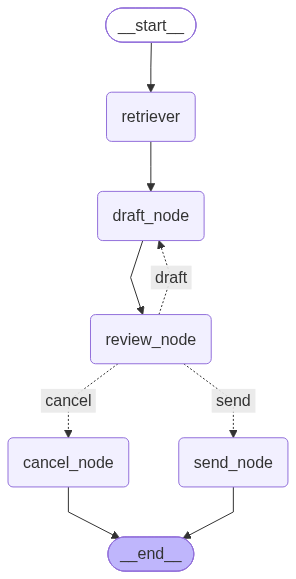

In [19]:
import agent
from agent import final_graph

# fina_graph mermaid diagram is failing b/c of some n/w error
final_graph

# Prints the text format of the diagram. Copy the output then open https://mermaid.live/. Paste it there. It will show you the picture of graph
# print(final_graph.get_graph().draw_mermaid())

In [20]:
res = final_graph.invoke(
    {
        "question": "I want to send the leave request from 12 Sep 2026 to 14 sep 2026. My manager name is 'Rahul Kumar' and email address is chetan99ai@gmail.com"
    },
    {
        "configurable": {"thread_id": "email_agent_conv_thrd_2"}
    }
)



--------------------------------------------------
Subject:  Leave Request for 12-14 September 2026 

Body: Dear Rahul Kumar,

I hope you are doing well. I would like to request leave from 12 September 2026 to 14 September 2026. I will ensure all my responsibilities are covered and will complete any pending tasks before my departure. Please let me know if you need any additional information.

Thank you for your consideration.

Best regards,
[Your Name]
--------------------------------------------------


In [21]:
from langgraph.types import Command

# When we invoke the workflow/langgraph with Command and resume then this time it will not go to the START node.
# It will go to the node that has got interrupt in it.
# The node that has got the conditional edge associated

# Run this if you want to test approve
# res = final_graph.invoke(
#     Command(resume="yes"),
#     {
#         "configurable": {"thread_id": "email_agent_conv_thrd_1"}
#     }
# )

# Run this if you want to test feedback and re-draft and agin send for feedback
res = final_graph.invoke(
    Command(resume="Complete email body is good. Just remove the placeholders and put my name there. Name is 'Chetan'"),
    {
        "configurable": {"thread_id": "email_agent_conv_thrd_2"}
    }
)



--------------------------------------------------
Subject:  Leave Request for 12-14 September 2026 

Body: Dear Rahul Kumar,

I hope you are doing well. I would like to request leave from 12 September 2026 to 14 September 2026. I will ensure all my responsibilities are covered and will complete any pending tasks before my departure. Please let me know if you need any additional information.

Thank you for your consideration.

Best regards,
[Your Name]
--------------------------------------------------


--------------------------------------------------
Subject:  Leave Request for 12–14 September 2026 

Body: Dear Rahul Kumar,

I hope you are doing well. I would like to request leave from 12 September 2026 to 14 September 2026. I will ensure all my responsibilities are covered and will complete any pending tasks before my departure. Please let me know if you need any additional information.

Thank you for your consideration.

Best regards,
Chetan
------------------------------------

In [22]:
# The response is set by the conditional edge's router.
# This time it will be empty because as per our current logic, we set the response as empty in the state: EmailState's object when a feedback is given
res["response"]

''

In [23]:
# Test the second time approval use case
# Now we should invoke the langgraph with Command resume="yes" so that the current logic in the conditional edge's router will send the email
res = final_graph.invoke(
    Command(resume="yes"),
    {
        "configurable": {"thread_id": "email_agent_conv_thrd_2"}
    }
)



--------------------------------------------------
Subject:  Leave Request for 12–14 September 2026 

Body: Dear Rahul Kumar,

I hope you are doing well. I would like to request leave from 12 September 2026 to 14 September 2026. I will ensure all my responsibilities are covered and will complete any pending tasks before my departure. Please let me know if you need any additional information.

Thank you for your consideration.

Best regards,
Chetan
--------------------------------------------------


In [24]:
# Now print the respose
res["response"]

'Email sent successfully!'